**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: José Carlos Sierra Pérez
*   MATRÍCULA: A01055689

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [48]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\jose.sierra\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [49]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

In [50]:
# Configuración auxiliar
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

pd.set_option('display.max_columns', None)
COLOR_SIN = '#2a78d6'   # registros SIN faltante (azul)
COLOR_CON = '#eb6834'   # registros CON faltante (naranja)

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [51]:
# Si trabajas en Google Colab con el archivo en Drive, descomenta y ajusta la ruta:
# from google.colab import drive
# drive.mount('/content/drive')
# import os
# os.chdir('/content/drive/MyDrive/<carpeta_de_la_actividad>')

cardio_df = pd.read_csv('heart_disease.csv')
cardio_df = cardio_df.set_index('id')   

print(f'Dimensiones: {cardio_df.shape[0]} registros x {cardio_df.shape[1]} columnas')
print(f'Rango de id: {cardio_df.index.min()} a {cardio_df.index.max()}')
cardio_df.head()

Dimensiones: 918 registros x 15 columnas
Rango de id: 1 a 920


,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [52]:
cardio_df.info()

<class 'pandas.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    str    
 2   origin    918 non-null    str    
 3   cp        918 non-null    str    
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    str    
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    str    
 12  ca        309 non-null    float64
 13  thal      434 non-null    str    
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(2), str(6)
memory usage: 114.8+ KB


In [53]:
# Clasificación de columnas según el tipo de dato que asignó pandas
cols_numericas = cardio_df.select_dtypes(include='number').columns.tolist()
cols_texto = cardio_df.select_dtypes(exclude='number').columns.tolist()

print(f'Columnas numéricas ({len(cols_numericas)}): {cols_numericas}')
print(f'Columnas de texto / object ({len(cols_texto)}): {cols_texto}')

# fbs y exang aparecen como object, pero su contenido es booleano (True/False) más NaN
for col in ['fbs', 'exang']:
    print(f'Tipos de Python presentes en {col}: {cardio_df[col].dropna().map(type).unique().tolist()}')

Columnas numéricas (7): ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num']
Columnas de texto / object (8): ['sex', 'origin', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']
Tipos de Python presentes en fbs: [<class 'bool'>]
Tipos de Python presentes en exang: [<class 'bool'>]


In [54]:
# Cantidad de valores únicos por columna (nunique no cuenta los NaN)
#valores_unicos = pd.DataFrame({
#    'tipo': cardio_df.dtypes.astype(str),
#    'valores_unicos': cardio_df.nunique()
#}).sort_values('valores_unicos')
#valores_unicos
#print(sum(valores_unicos))

# Cantidad de valores únicos por columna (nunique no cuenta los NaN)
valores_unicos = pd.DataFrame({
    'tipo': cardio_df.dtypes.astype(str),
    'valores_unicos': cardio_df.nunique()
}).sort_values('valores_unicos')
display(valores_unicos)
print('Total de valores únicos:', valores_unicos['valores_unicos'].sum())

print('Registros totales              :', len(cardio_df))
print('Rango de id                    :', cardio_df.index.min(), 'a', cardio_df.index.max())
print('id únicos                      :', cardio_df.index.nunique())
print('Registros duplicados           :', cardio_df.duplicated().sum())
print('Registros únicos (sin duplicar):', len(cardio_df.drop_duplicates()))

# id que faltan dentro del rango
ids_faltantes = sorted(set(range(cardio_df.index.min(), cardio_df.index.max() + 1)) - set(cardio_df.index))
print('id faltantes en el rango       :', ids_faltantes)



,tipo,valores_unicos
sex,str,2
fbs,object,2
exang,object,2
restecg,str,3
slope,str,3
thal,str,3
cp,str,4
origin,str,4
ca,float64,4
num,int64,5


Total de valores únicos: 530
Registros totales              : 918
Rango de id                    : 1 a 920
id únicos                      : 918
Registros duplicados           : 2
Registros únicos (sin duplicar): 916
id faltantes en el rango       : [572, 599]


In [55]:
print('Versión de pandas:', pd.__version__)

# 1) Columnas no numéricas
print('\n1) Contenido columnas no numéricas')
cols_texto = cardio_df.select_dtypes(exclude='number').columns
for col in cols_texto:
    tipos = sorted({type(v).__name__ for v in cardio_df[col].dropna()})
    print(f'   {col:8s} dtype = {str(cardio_df[col].dtype):7s} | tipos = {tipos} | NaN = {cardio_df[col].isna().sum()}')

booleanas = [c for c in cols_texto if cardio_df[c].dropna().map(type).eq(bool).all()]
cadenas = [c for c in cols_texto if c not in booleanas]
print(f'   -> {len(cadenas)} de cadenas: {cadenas}')
print(f'   -> {len(booleanas)} booleanas guardadas como object: {booleanas}')

# 2) Columnas float64
print('\n2) Columnas float64')
for col in cardio_df.select_dtypes(include='float').columns:
    s = cardio_df[col].dropna()
    print(f'   {col:8s} solo enteros = {str((s % 1 == 0).all()):5s} | NaN = {cardio_df[col].isna().sum()}')

# 3) probar
print('\n3) Prueba')
try:
    cardio_df['trestbps'].astype('int64')
except Exception as e:
    print('   trestbps -> int64:', type(e).__name__, '-', e)
print('   fbs -> bool convierte los NaN en:', cardio_df['fbs'].astype(bool)[cardio_df['fbs'].isna()].unique())

Versión de pandas: 3.0.2

1) Contenido columnas no numéricas
   sex      dtype = str     | tipos = ['str'] | NaN = 0
   origin   dtype = str     | tipos = ['str'] | NaN = 0
   cp       dtype = str     | tipos = ['str'] | NaN = 0
   fbs      dtype = object  | tipos = ['bool'] | NaN = 89
   restecg  dtype = str     | tipos = ['str'] | NaN = 0
   exang    dtype = object  | tipos = ['bool'] | NaN = 55
   slope    dtype = str     | tipos = ['str'] | NaN = 308
   thal     dtype = str     | tipos = ['str'] | NaN = 484
   -> 6 de cadenas: ['sex', 'origin', 'cp', 'restecg', 'slope', 'thal']
   -> 2 booleanas guardadas como object: ['fbs', 'exang']

2) Columnas float64
   trestbps solo enteros = True  | NaN = 59
   chol     solo enteros = True  | NaN = 30
   thalch   solo enteros = True  | NaN = 55
   oldpeak  solo enteros = False | NaN = 62
   ca       solo enteros = True  | NaN = 609

3) Prueba
   trestbps -> int64: IntCastingNaNError - Cannot convert non-finite values (NA or inf) to integer.R

**Respuestas – Pregunta 1**

* Se cargaron **918 registros** y, al usar `id` como índice, quedan **15 columnas**. Los `id` van de 1 a 920. Faltan dos identificadores (572 y 599), así que el índice no es consecutivo.
* **¿Cuántas columnas son numéricas y cuántas de texto?** Según `info()` hay **7 columnas numéricas** y **8 de texto (`object`)**:
  * Numéricas (7): `age` y `num` (`int64`), y `trestbps`, `chol`, `thalch`, `oldpeak` y `ca` (`float64`).
  * Texto / `object` (8): `sex`, `origin`, `cp`, `fbs`, `restecg`, `exang`, `slope` y `thal`.
* Dos precisiones sobre los tipos:
  * `fbs` y `exang` no contienen texto libre. Son **booleanos**  entiendo que pandas guarda como `object` porque tienen NaN, y el tipo `bool` no admite faltantes. Por eso, de las 8 columnas "de texto", 6 son algo como `str` y 2 son booleanas.
  * `trestbps`, `chol`, `thalch` y `ca` solo toman valores enteros, pero aparecen como `float64` por la misma razón: `int64` no admite NaN.
* **Valores únicos por columna:** `sex`, `fbs` y `exang` tienen 2. `restecg`, `slope` y `thal` tienen 3. `origin`, `cp` y `ca` tienen 4, y `num` tiene 5. Las variables continuas tienen muchos más: `age` 50, `oldpeak` 53, `trestbps` 60, `thalch` 119 y `chol` 216.

Rspecto de los **booleanos**:

`fbs` y `exang` son booleanos que pandas guarda como `object` porque contienen NaN: los tipos booleano y entero de NumPy no pueden almacenar faltantes, por lo que pandas promueve `boolean → object` e `integer → float64` (pandas development team, 2023a, 2023b). No se si estoy interpretando bien esto como parte de la tarea pero quise agregarlo en caso de que hubiera que hacerlo notar. 

**Referencias**

pandas development team. (2023a). *Working with missing data* (Versión 2.1) [Documentación].
https://pandas.pydata.org/pandas-docs/version/2.1/user_guide/missing_data.html

pandas development team. (2023b). *Frequently Asked Questions (FAQ): NA type promotions*
(Versión 2.1) [Documentación]. https://pandas.pydata.org/pandas-docs/version/2.1/user_guide/gotchas.html

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [56]:
# Valores únicos de las columnas numéricas, de menor a mayor
cardio_df[cols_numericas].nunique().sort_values()

ca            4
num           5
age          50
oldpeak      53
trestbps     60
thalch      119
chol        216
dtype: int64

In [57]:
# Valores que toman las numéricas con pocos valores únicos
for col in ['ca', 'num']:
    print(f'{col}: {sorted(cardio_df[col].dropna().unique())}')

ca: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]
num: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


 como dos de las variables numéricas tienen pocos valores únicos supuse que son categóricas codificadas como números. Las otras cinco (`age`, `oldpeak`, `trestbps`, `thalch` y `chol`, con 50 o más valores distintos) son continuas y se quedan como numéricas.


 `ca`  0, 1, 2, 3   **Ordinal**: 0 < 1 < 2 < 3.  
`num`  0, 1, 2, 3, 4  **Ordinal**: 0 < 1 < 2 < 3 < 4.  


In [58]:
# Conversión a categóricas 
ca_tipo = pd.CategoricalDtype(categories=[0, 1, 2, 3], ordered=True)
num_tipo = pd.CategoricalDtype(categories=[0, 1, 2, 3, 4], ordered=True)

# ca es float64 
cardio_df['ca'] = cardio_df['ca'].astype('Int64').astype(ca_tipo)
cardio_df['num'] = cardio_df['num'].astype(num_tipo)

for col in ['ca', 'num']:
    print(f'{col}: ordenada = {cardio_df[col].cat.ordered}, '
          f'categorías = {list(cardio_df[col].cat.categories)}, faltantes = {cardio_df[col].isna().sum()}')

ca: ordenada = True, categorías = [0, 1, 2, 3], faltantes = 609
num: ordenada = True, categorías = [0, 1, 2, 3, 4], faltantes = 0


**Complemento:** para que el análisis por tipo de variable sea coherente, las columnas de texto y las booleanas también se convierten a `category`, y se distingue cuáles son nominales y cuáles ordinales:

* **Nominales:** `sex`, `origin`, `restecg`, `thal`, `fbs` y `exang`, `cp` num` 
* **Ordinal:** `slope`, 

In [59]:
for col in ['sex', 'origin', 'cp', 'restecg', 'thal']:
    cardio_df[col] = cardio_df[col].astype('category')

# Binarias: categorías explícitas [False, True]; los NaN se conservan
for col in ['fbs', 'exang']:
    cardio_df[col] = cardio_df[col].astype(pd.CategoricalDtype(categories=[False, True]))

cardio_df['slope'] = cardio_df['slope'].astype(
    pd.CategoricalDtype(categories=['upsloping', 'flat', 'downsloping'], ordered=True))

cardio_df.dtypes

age            int64
sex         category
origin      category
cp          category
trestbps     float64
chol         float64
fbs         category
restecg     category
thalch       float64
exang       category
oldpeak      float64
slope       category
ca          category
thal        category
num         category
dtype: object

**Respuesta – Pregunta 2:** sí hay variables numéricas que en realidad son categóricas: **`ca`** (4 valores) y **`num`** (5 valores) (tuve que checar esto porque no tenía claro) Ambas son **ordinales** y se convirtieron a `category` con `ordered=True` y el orden 0 < 1 < … . Como complemento, las columnas de texto y booleanas también se pasaron a `category`. `slope` quedó como ordinal y el resto como nominales.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [60]:
cols_numericas = cardio_df.select_dtypes(include='number').columns.tolist()
cols_categoricas = cardio_df.select_dtypes(exclude='number').columns.tolist()
print('Numéricas  :', cols_numericas)
print('Categóricas:', cols_categoricas)

Numéricas  : ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
Categóricas: ['sex', 'origin', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'num']


**3.1 Variables numéricas**

In [61]:
# Estadísticas descriptivas 
desc_num = cardio_df[cols_numericas].describe().T
desc_num['sesgo'] = cardio_df[cols_numericas].skew()
desc_num['curtosis'] = cardio_df[cols_numericas].kurt()   # curtosis en exceso (Fisher): normal = 0
desc_num.round(3)

,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
age,918.0,53.531,9.413,28.0,47.0,54.0,60.0,77.0,-0.194,-0.383
trestbps,859.0,132.295,18.536,80.0,120.0,130.0,140.0,200.0,0.630,0.633
chol,888.0,242.189,53.425,85.0,216.0,223.0,268.0,603.0,1.641,6.574
thalch,863.0,137.528,25.950,60.0,120.0,140.0,157.0,202.0,-0.209,-0.484
oldpeak,856.0,0.881,1.092,-2.6,0.0,0.5,1.5,6.2,1.038,1.120


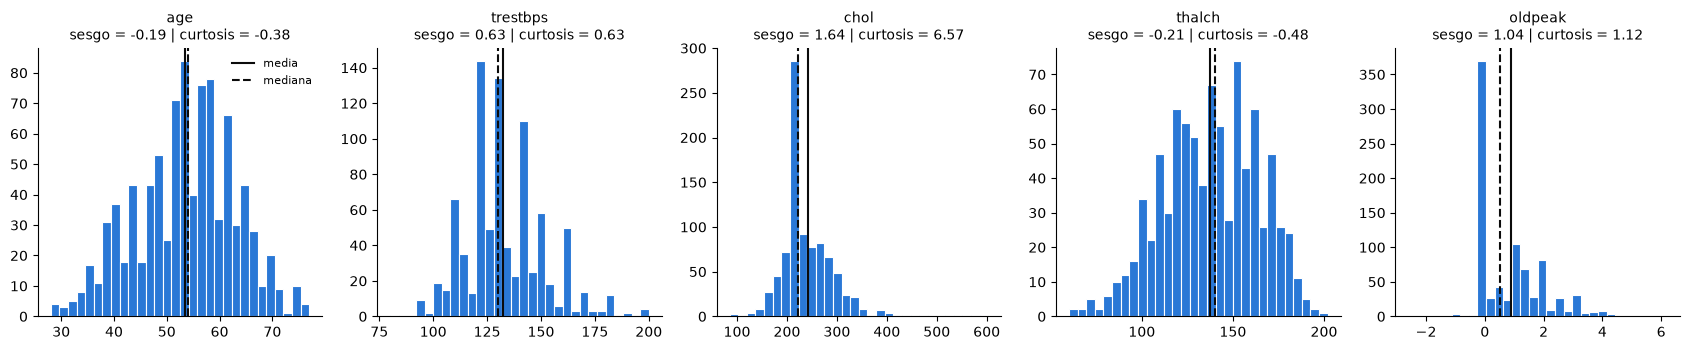

In [62]:

fig, axes = plt.subplots(1, len(cols_numericas), figsize=(17, 3.6))
for ax, col in zip(axes, cols_numericas):
    ax.hist(cardio_df[col].dropna(), bins=30, color=COLOR_SIN, edgecolor='white', linewidth=0.8)
    ax.axvline(cardio_df[col].mean(), color='#0b0b0b', lw=1.5, label='media')
    ax.axvline(cardio_df[col].median(), color='#0b0b0b', lw=1.5, ls='--', label='mediana')
    ax.set_title(f'{col}\nsesgo = {cardio_df[col].skew():.2f} | curtosis = {cardio_df[col].kurt():.2f}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Interpretación (numéricas):**

* **`age`**: media 53.5 y mediana 54. Sesgo −0.19 y curtosis −0.38, así que es prácticamente simétrica y algo más aplanada (no es el térimno técnico pero es como coloquialmente he escuchado que se usa) que una normal.
* **`trestbps`**: media 132.3 y mediana 130. Sesgo positivo moderado (0.63), con una cola alargada hacia valores más altos (máximo 200).
* **`chol`**: media 242.2 por encima de la mediana de 223. Tiene **fuerte asimetría a la derecha (1.64) y colas muy pesadas (curtosis 6.57)**, con un máximo de 603. Es la variable con más probabilidad de tener atípicos.
* **`thalch`**: media 137.5 y mediana 140. Casi simétrica, con una ligera cola izquierda (−0.21) por algunos valores bajos.
* **`oldpeak`**: media 0.88 y mediana 0.5. Sesgo positivo (1.04)

*Nota/ fun fact:* `kurt()` de pandas reporta la curtosis **en exceso** de Fisher, es decir reporta el valor de 0 cuando corresponde a una distribución normal, la curtosis sin este cambio se reportaba con valores que para la distribución normal daba como resultado exactametne 3 

**3.2 Variables categóricas**

In [63]:
cardio_df[cols_categoricas].describe()

,sex,origin,cp,fbs,restecg,exang,slope,ca,thal,num
count,918,918,918,829,918,863,610,309,434,918
unique,2,4,4,2,3,2,3,4,3,5
top,Male,Cleveland,asymptomatic,False,normal,False,flat,0,normal,0
freq,724,304,495,691,551,526,345,181,196,411


In [64]:
# Tablas de frecuencia absoluta y relativa (incluyendo faltantes, NaN).
# Las ordinales se muestran en su orden natural; las nominales, por frecuencia.
for col in cols_categoricas:
    ordenar_por_frecuencia = not cardio_df[col].cat.ordered
    frec = cardio_df[col].value_counts(dropna=False, sort=ordenar_por_frecuencia)
    tabla = pd.DataFrame({'frecuencia': frec,
                          'porcentaje': (frec / len(cardio_df) * 100).round(2)})
    tabla.index.name = col
    print(f'\n===== {col} =====')
    print(tabla.to_string())


===== sex =====
        frecuencia  porcentaje
sex                           
Male           724       78.87
Female         194       21.13

===== origin =====
               frecuencia  porcentaje
origin                               
Cleveland             304       33.12
Hungary               292       31.81
VA Long Beach         200       21.79
Switzerland           122       13.29

===== cp =====
                 frecuencia  porcentaje
cp                                     
asymptomatic            495       53.92
non-anginal             204       22.22
atypical angina         174       18.95
typical angina           45        4.90

===== fbs =====
       frecuencia  porcentaje
fbs                          
False         691       75.27
True          138       15.03
NaN            89        9.69

===== restecg =====
                  frecuencia  porcentaje
restecg                                 
normal                   551       60.02
lv hypertrophy           188       20.48
st-

**Interpretación (categóricas):**

* **`sex`**: muy desbalanceada por sexo
* **`origin`**: Cleveland 33.1%, Hungary 31.8%, VA Long Beach 21.8% y Switzerland 13.3%. 
* **`cp`**: predomina *asymptomatic* (53.9%).
* **`fbs`**: 75.3% False, 15.0% True y 9.7% faltante.
* **`restecg`**: 60.0% normal, 20.5% lv hypertrophy  y 19.5% st-t abnormality.
* **`exang`**: 57.3% False, 36.7% True y 6.0% faltante.
* **`slope`, `ca` y `thal`**: su categoría más frecuente es **NaN** (33.6%, 66.3% y 52.7%)
* **`num`** (objetivo): 44.8% sanos (0) y 55.2% con algún grado de enfermedad. Como variable binaria está razonablemente balanceada, pero como multiclase no: el grado 4 solo tiene 28 casos (3.1%).

**3.3 Observación de calidad de datos (`chol`)**

En la tabla de la sección 3.1, la mediana de `chol` (223) queda sospechosamente pegada a su primer cuartil (216), y el histograma muestra un pico aislado en ese valor. A continuación se revisa.

In [65]:
print('Valores más frecuentes de chol:')
print(cardio_df['chol'].value_counts().head(5))
pd.crosstab(cardio_df['origin'], cardio_df['chol'].eq(223).rename('chol == 223'), margins=True)

Valores más frecuentes de chol:
chol
223.0    180
254.0     10
220.0     10
204.0      9
211.0      9
Name: count, dtype: int64


chol == 223,False,True,All
origin,,,
Cleveland,301,3,304
Hungary,289,3,292
Switzerland,0,122,122
VA Long Beach,148,52,200
All,738,180,918


**180 registros (19.6%) tienen exactamente 223**, mientras que el siguiente valor más frecuente aparece solo 10 veces. Además, **los 122 pacientes de Switzerland** y 52 de VA Long Beach comparten ese valor. 

Cuando pedíayuda con la interpretación de esto Claude me hizo notar que una coincidencia así no es fisiológicamente plausible: por eso y casi con seguridad son **valores no medidos que se sustituyeron por una constante**. Además le dí contexto del notebook y señaló que en la versión pública original de este conjunto (UCI/Kaggle), el colesterol no medido se registraba como 0. (esto lo revisó claude porque era una distribución extraña)

Implicaciones:

* La tasa real de faltantes de `chol` no es 3.3%, sino cerca de **22%** (30 NaN más unos 174 valores de relleno).
* El pico en 223 comprime el IQR y sesga la mediana. Sin esos registros, la mediana sería de 240 y la media de 246.9.
* Los resultados de las preguntas 5, 7 y 8 que involucran `chol` deben leerse con esta reserva.

En esta actividad **se conserva el dato tal como viene**, para no alterar el flujo que se evalúa. En un análisis real, recodificaría como NaN el valor 223 de Switzerland y VA Long Beach antes de imputar. Quiero enfatizar el uso de AI para esto pues me apreció algo que es muy poco factible que a mi me hubiese parecido notable. 

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [66]:
faltantes = pd.DataFrame({
    'n_faltantes': cardio_df.isna().sum(),
    'porcentaje': cardio_df.isna().mean().mul(100).round(2)
}).sort_values('porcentaje', ascending=False)
faltantes

,n_faltantes,porcentaje
ca,609,66.34
thal,484,52.72
slope,308,33.55
fbs,89,9.69
oldpeak,62,6.75
trestbps,59,6.43
thalch,55,5.99
exang,55,5.99
chol,30,3.27
sex,0,0.00


In [67]:
UMBRAL = 30
cols_eliminar = faltantes.index[faltantes['porcentaje'] > UMBRAL].tolist()
print(f'Columnas con más de {UMBRAL}% de faltantes (se eliminan): {cols_eliminar}')

cardio_df = cardio_df.drop(columns=cols_eliminar)
print(f'Dimensiones después de eliminarlas: {cardio_df.shape}')

Columnas con más de 30% de faltantes (se eliminan): ['ca', 'thal', 'slope']
Dimensiones después de eliminarlas: (918, 12)


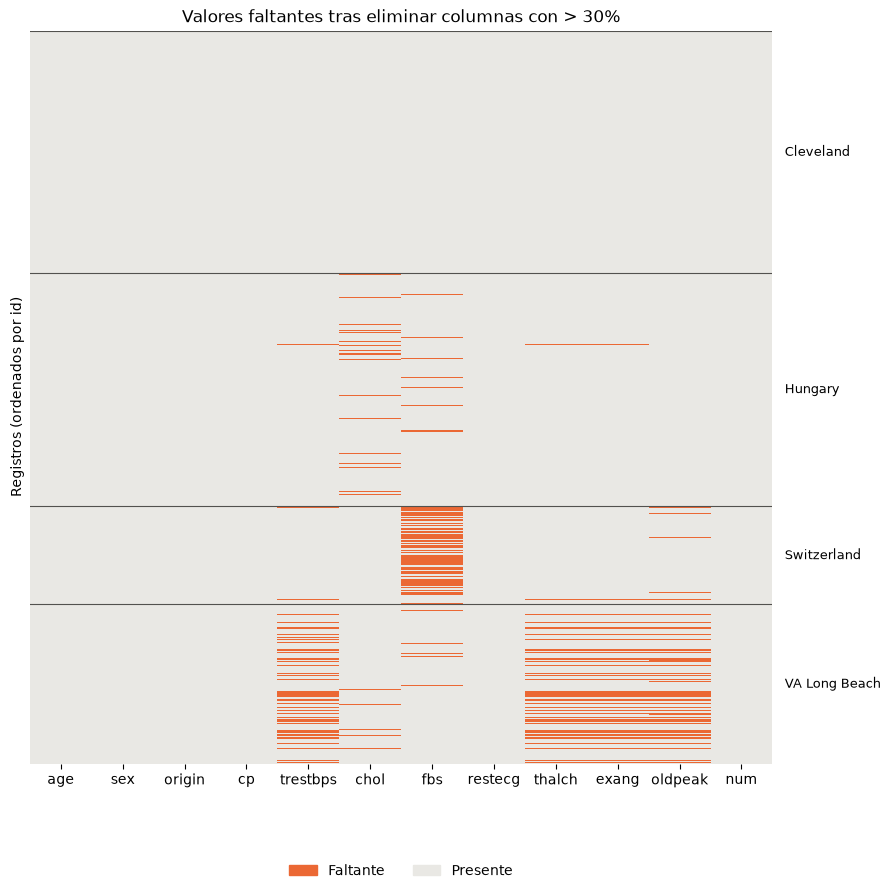

In [68]:
def graficar_faltantes(df, titulo):
    """Mapa de calor de faltantes; marca los bloques de cada centro (origin)."""
    fig, ax = plt.subplots(figsize=(9, 9))
    sns.heatmap(df.isna(), cmap=ListedColormap(['#e9e8e4', COLOR_CON]), vmin=0, vmax=1,
                cbar=False, yticklabels=False, ax=ax)
    # líneas y etiquetas por centro (los registros vienen agrupados por origin)
    inicios = np.flatnonzero(df['origin'].ne(df['origin'].shift()).to_numpy())
    fines = np.append(inicios[1:], len(df))
    for ini, fin in zip(inicios, fines):
        ax.axhline(ini, color='#52514e', lw=0.8)
        ax.text(df.shape[1] + 0.2, (ini + fin) / 2, df['origin'].iloc[ini], va='center', fontsize=9)
    ax.set_title(titulo)
    ax.set_ylabel('Registros (ordenados por id)')
    ax.legend(handles=[Patch(color=COLOR_CON, label='Faltante'), Patch(color='#e9e8e4', label='Presente')],
              loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()

graficar_faltantes(cardio_df, 'Valores faltantes tras eliminar columnas con > 30%')

In [69]:
# Cuantificación de la concurrencia: matriz de faltantes simultáneos
# (diagonal = faltantes de cada variable; fuera de la diagonal = filas donde ambas faltan a la vez)
cols_con_nan = cardio_df.columns[cardio_df.isna().any()].tolist()
mv = cardio_df[cols_con_nan].isna().astype(int)
coocurrencia = mv.T @ mv
coocurrencia

,trestbps,chol,fbs,thalch,exang,oldpeak
trestbps,59,3,1,55,55,55
chol,3,30,0,3,3,3
fbs,1,0,89,0,0,4
thalch,55,3,0,55,55,54
exang,55,3,0,55,55,54
oldpeak,55,3,4,54,54,62


In [70]:
# Porcentaje de faltantes por centro de estudio
cardio_df[cols_con_nan].isna().groupby(cardio_df['origin'], observed=True).mean().mul(100).round(1)

,trestbps,chol,fbs,thalch,exang,oldpeak
origin,,,,,,
Cleveland,0.0,0.0,0.0,0.0,0.0,0.0
Hungary,0.3,7.9,2.7,0.3,0.3,0.0
Switzerland,1.6,0.0,60.7,0.8,0.8,4.9
VA Long Beach,28.0,3.5,3.5,26.5,26.5,28.0


**Respuestas – Pregunta 4**

**Porcentaje de faltantes:** `ca` 66.34%, `thal` 52.72%, `slope` 33.55%, `fbs` 9.69%, `oldpeak` 6.75%, `trestbps` 6.43%, `thalch` 5.99%, `exang` 5.99% y `chol` 3.27%. Las demás columnas no tienen faltantes.

**Columnas eliminadas (> 30%):** `ca`, `thal` y `slope`. Quedan 12 columnas.

**Variables con faltantes simultáneos:** **`thalch`, `exang`, `oldpeak` y `trestbps`**. En el mapa de calor forman un bloque horizontal, casi todo dentro de VA Long Beach, y la matriz de concurrencia lo confirma:

* `thalch` y `exang` faltan exactamente en las mismas **55 filas**.
* `oldpeak` falta en 54 de esas 55, y `trestbps` en las 55.
* 53 de las 55 filas son de **VA Long Beach** (26.5% de sus pacientes). En los demás centros, `thalch` y `exang` faltan en menos de 1% de los pacientes.

No forman parte del patrón `fbs` (89 faltantes, ninguno coincide con `thalch`; 74 son de Switzerland, el 61% de ese centro) ni `chol` (30 faltantes, solo 3 coinciden).

**¿Tiene sentido clínico la concurrencia? Según Claude Sí.**

1. `thalch`, `exang` y `oldpeak` son tres resultados de **un mismo procedimiento**, la **prueba de esfuerzo** (ergometría con electrocardiograma):
   * `thalch` es la frecuencia cardiaca máxima alcanzada durante el ejercicio.
   * `exang` indica si el ejercicio provocó angina.
   * `oldpeak` es la depresión del ST inducida por el ejercicio respecto al reposo.

   Si la prueba no se hizo, o su registro no se captura, las tres faltan a la vez. al parecer no una coincidencia.

2. Al aprecer hayy razones clínicas habituales para no realizar la prueba: **contraindicaciones** (angina inestable, infarto reciente, hipertensión no controlada, estenosis aórtica severa, insuficiencia cardiaca descompensada), **incapacidad para ejercitarse** (edad avanzada, limitaciones osteomusculares) o la decisión de pasar directamente a otro estudio, como el cateterismo.

3. `trestbps` entendí la presión en reposo y se suele registrar como valor basal al inicio del protocolo de esfuerzo. Que falte justo en los mismos 55 pacientes sugiere que se perdió o no se capturó **toda la hoja de la prueba**, incluida la presión basal. Eso apunta, sobre todo, a una **práctica de registro de un centro** (VA Long Beach) más que a decisiones clínicas caso por caso.

4. La misma lógica explica las columnas eliminadas. `slope` también sale del ECG de esfuerzo. `ca` (fluoroscopía o angiografía) y `thal` (gammagrafía con talio) son estudios costosos o invasivos (estos solo se registraron en Cleveland).

Quiero añadir que no había escuchado sobre casi ninguno los términos clinicos pero me valí de la asistencia de Claude para ello. Si hubiese tenido más tiempo me hubiera gustado constatar que es correcto. 

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

*Nota sobre las funciones:* se reutilizan `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` del Hands-On con **dos ajustes mínimos** en la primera, que no cambian su lógica:

1. `pd.Series('', ..., dtype=object)`: con pandas ≥ 3.0 el tipo por defecto de esa Serie es `str` y la función falla al guardar Series dentro (`TypeError`). Con `dtype=object` funciona igual en pandas 2.x y 3.x.
2. `plt.xlim = att_range` → `plt.xlim(att_range)`: la línea original **sustituía la función `plt.xlim` por una tupla**. No fijaba el rango y, además, rompía cualquier llamada posterior a `plt.xlim()`. Con la corrección, los dos histogramas comparten la escala del eje x, que es lo que se buscaba.

In [71]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique(), dtype=object)   # [ajuste 1] dtype=object
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim(att_range)                                          # [ajuste 2] antes: plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [72]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

**5.1 División en grupos: con y sin faltante en `thalch`**

In [73]:
BM_MV = cardio_df['thalch'].isna()      # True = thalch faltante
print(BM_MV.value_counts().rename(index={True: 'Con faltante en thalch', False: 'Sin faltante en thalch'}))

thalch
Sin faltante en thalch    863
Con faltante en thalch     55
Name: count, dtype: int64


**5.2 Variables numéricas (`age`, `chol`): boxplots, histogramas y prueba t**

Diagnóstico de los faltantes de thalch respecto a age:


C:\Users\jose.sierra\AppData\Local\Temp\ipykernel_40236\80939964.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(box_sr,vert=False)


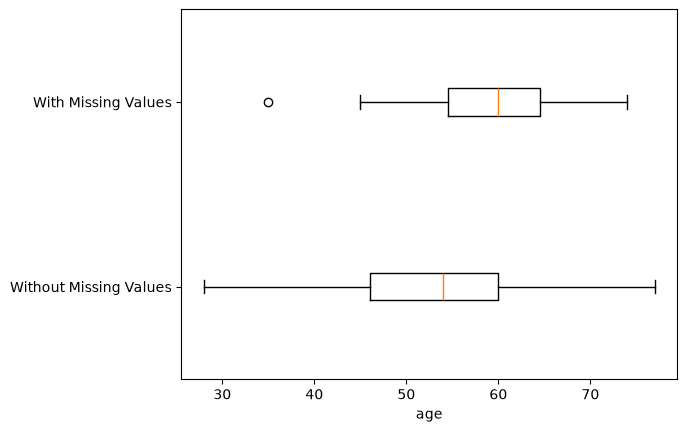

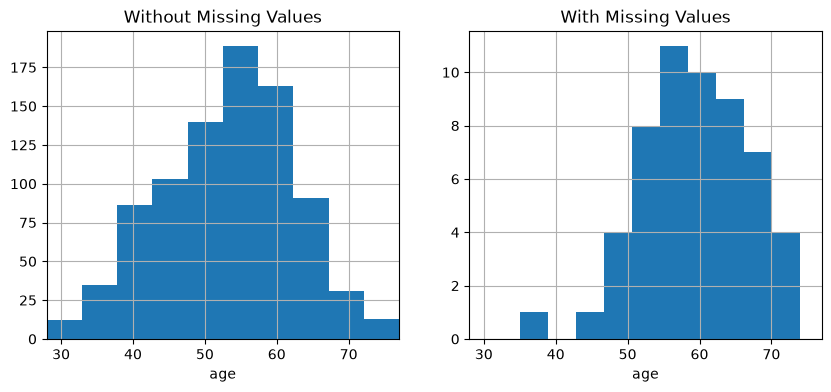

p-value of t-test: 1.5041244185890923e-06
- - - - - - - - - - - - divider - - - - - - - - - - - 
Diagnóstico de los faltantes de thalch respecto a chol:


C:\Users\jose.sierra\AppData\Local\Temp\ipykernel_40236\80939964.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(box_sr,vert=False)


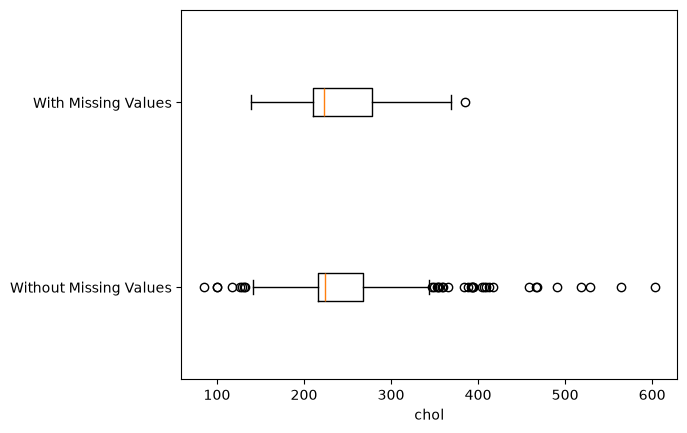

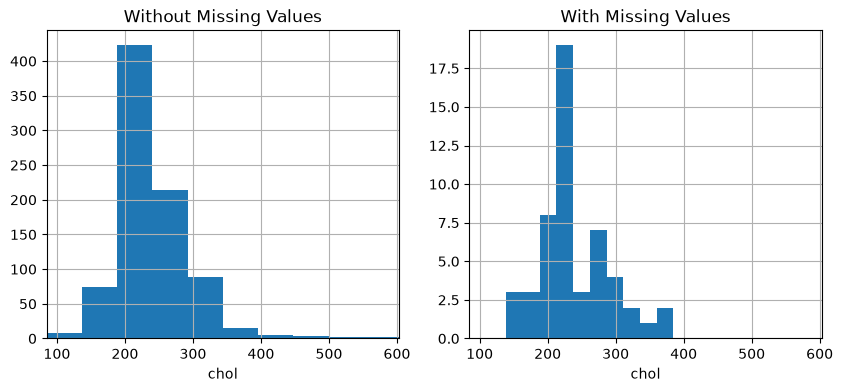

p-value of t-test: 0.7165289974295669
- - - - - - - - - - - - divider - - - - - - - - - - - 


In [74]:
numerical_attributes = ['age', 'chol']

for att in numerical_attributes:
    print(f'Diagnóstico de los faltantes de thalch respecto a {att}:')
    Diagnose_MV_Numerical(cardio_df, att, BM_MV)
    print('- - - - - - - - - - - - divider - - - - - - - - - - - ')

**5.3 Variables categóricas (`restecg`, `cp`): gráficas de barras y prueba χ²**

Diagnóstico de los faltantes de thalch respecto a restecg:


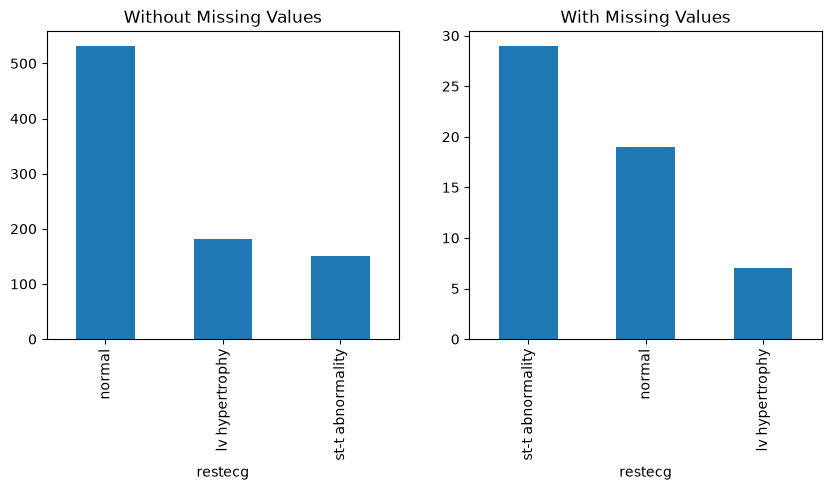

p-value of Chi_squared test: 1.1472889573985467e-09
- - - - - - - - - - - - divider - - - - - - - - - - - 
Diagnóstico de los faltantes de thalch respecto a cp:


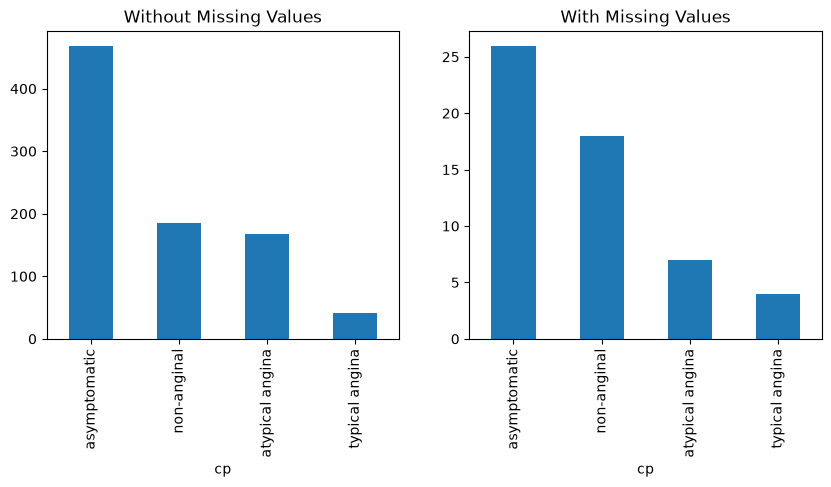

p-value of Chi_squared test: 0.15420097177251701
- - - - - - - - - - - - divider - - - - - - - - - - - 


In [75]:
categorical_attributes = ['restecg', 'cp']

for att in categorical_attributes:
    print(f'Diagnóstico de los faltantes de thalch respecto a {att}:')
    Diagnose_MV_Categorical(cardio_df, att, BM_MV)
    print('- - - - - - - - - - - - divider - - - - - - - - - - - ')

**5.4 Complementos: robustez de las pruebas y comparación de proporciones**

Las gráficas de barras de `Diagnose_MV_Categorical` ordenan cada panel por frecuencia y usan conteos absolutos: 55 contra 863 registros, con un orden de categorías distinto en cada panel. Eso dificulta la comparación. Por eso se agregan proporciones con el mismo orden y se revisan los supuestos de las pruebas.

In [76]:
from scipy.stats import mannwhitneyu, levene, chi2_contingency

# Numéricas: t de Student (la de la función), t de Welch (sin suponer varianzas iguales)
# y Mann-Whitney (no paramétrica)
filas = []
for att in numerical_attributes:
    con = cardio_df.loc[BM_MV, att].dropna()
    sin = cardio_df.loc[~BM_MV, att].dropna()
    filas.append({'variable': att,
                  'n_con': len(con), 'n_sin': len(sin),
                  'media_con': round(con.mean(), 2), 'media_sin': round(sin.mean(), 2),
                  'mediana_con': con.median(), 'mediana_sin': sin.median(),
                  'p_t_Student': ttest_ind(con, sin).pvalue,
                  'p_t_Welch': ttest_ind(con, sin, equal_var=False).pvalue,
                  'p_Mann_Whitney': mannwhitneyu(con, sin).pvalue,
                  'p_Levene': levene(con, sin).pvalue})
pd.DataFrame(filas).set_index('variable')

,n_con,n_sin,media_con,media_sin,mediana_con,mediana_sin,p_t_Student,p_t_Welch,p_Mann_Whitney,p_Levene
variable,,,,,,,,,,
age,55,863,59.42,53.16,60.0,54.0,0.000002,4.115876e-07,0.000002,0.105901
chol,52,836,239.58,242.35,223.0,224.0,0.716529,7.104716e-01,0.599278,0.861598


In [77]:
# Categóricas: proporciones dentro de cada grupo y supuesto de frecuencias esperadas de la chi-cuadrada
for att in categorical_attributes:
    tabla = pd.crosstab(BM_MV, cardio_df[att])
    chi2, p, gl, esperadas = chi2_contingency(tabla)
    print(f'===== {att}: chi2 = {chi2:.2f}, gl = {gl}, p-value = {p:.3g} =====')
    print(pd.crosstab(BM_MV.rename('thalch faltante'), cardio_df[att], normalize='index').mul(100).round(1).to_string())
    print(f'Celdas con frecuencia esperada < 5: {(esperadas < 5).sum()} de {esperadas.size} '
          f'(mínima = {esperadas.min():.2f})\n')

===== restecg: chi2 = 41.17, gl = 2, p-value = 1.15e-09 =====
restecg          lv hypertrophy  normal  st-t abnormality
thalch faltante                                          
False                      21.0    61.6              17.4
True                       12.7    34.5              52.7
Celdas con frecuencia esperada < 5: 0 de 6 (mínima = 10.72)

===== cp: chi2 = 5.25, gl = 3, p-value = 0.154 =====
cp               asymptomatic  atypical angina  non-anginal  typical angina
thalch faltante                                                            
False                    54.3             19.4         21.6             4.8
True                     47.3             12.7         32.7             7.3
Celdas con frecuencia esperada < 5: 1 de 8 (mínima = 2.70)



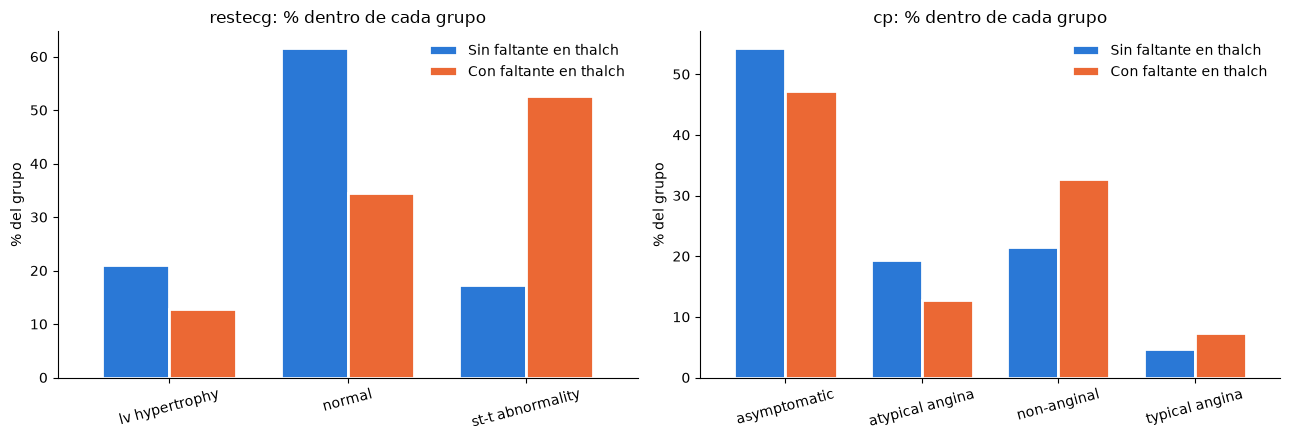

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, att in zip(axes, categorical_attributes):
    prop = pd.crosstab(cardio_df[att], BM_MV, normalize='columns').mul(100)
    prop = prop.rename(columns={False: 'Sin faltante en thalch', True: 'Con faltante en thalch'})
    prop.plot.bar(ax=ax, color=[COLOR_SIN, COLOR_CON], width=0.75, edgecolor='white', linewidth=2)
    ax.set_title(f'{att}: % dentro de cada grupo')
    ax.set_ylabel('% del grupo')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**5.5 ¿Qué hay detrás de las diferencias? El centro de estudio (`origin`)**

In [79]:
display(pd.crosstab(cardio_df['origin'], BM_MV.rename('thalch faltante'), margins=True))
print('p-value chi-cuadrada (origin):', chi2_contingency(pd.crosstab(BM_MV, cardio_df['origin']))[1])
print('\nEdad media por centro:')
print(cardio_df.groupby('origin', observed=True)['age'].mean().round(1).to_string())

thalch faltante,False,True,All
origin,,,
Cleveland,304,0,304
Hungary,291,1,292
Switzerland,121,1,122
VA Long Beach,147,53,200
All,863,55,918


p-value chi-cuadrada (origin): 3.5936809000787185e-41

Edad media por centro:
origin
Cleveland        54.4
Hungary          47.9
Switzerland      55.5
VA Long Beach    59.4


In [80]:
# Análisis estratificado: solo VA Long Beach (donde están 53 de los 55 faltantes)
va = cardio_df['origin'] == 'VA Long Beach'
print(f'VA Long Beach: {va.sum()} pacientes, {BM_MV[va].sum()} con thalch faltante\n')
for att in numerical_attributes:
    p = ttest_ind(cardio_df.loc[va & BM_MV, att].dropna(), cardio_df.loc[va & ~BM_MV, att].dropna()).pvalue
    print(f'{att:8s} -> p-value t-test dentro de VA Long Beach = {p:.3f}')
for att in categorical_attributes:
    tabla_va = pd.crosstab(BM_MV[va], cardio_df.loc[va, att])
    _, p, _, esperadas = chi2_contingency(tabla_va)
    print(f'{att:8s} -> p-value chi-cuadrada dentro de VA Long Beach = {p:.3f} '
          f'(celdas con esperada < 5: {(esperadas < 5).sum()} de {esperadas.size})')

VA Long Beach: 200 pacientes, 53 con thalch faltante

age      -> p-value t-test dentro de VA Long Beach = 0.911
chol     -> p-value t-test dentro de VA Long Beach = 0.573
restecg  -> p-value chi-cuadrada dentro de VA Long Beach = 0.733 (celdas con esperada < 5: 0 de 6)
cp       -> p-value chi-cuadrada dentro de VA Long Beach = 0.010 (celdas con esperada < 5: 2 de 8)


**Conclusiones – Pregunta 5** (α = 0.05)

| Variable | Gráfica | Prueba | p-value | ¿Diferencia significativa? |
|---|---|---|---|---|
| `age` | Boxplot e histograma desplazados a la derecha en el grupo con faltantes | t de Student | 1.5 × 10⁻⁶ | **Sí**: los pacientes sin `thalch` son mayores (media 59.4 contra 53.2 años) |
| `chol` | Boxplots e histogramas prácticamente superpuestos | t de Student | 0.717 | **No**: 239.6 contra 242.4 mg/dl |
| `restecg` | La anomalía ST-T está sobrerrepresentada en el grupo con faltantes | χ² | 1.1 × 10⁻⁹ | **Sí**: ST-T en 52.7% contra 17.4% |
| `cp` | Perfiles parecidos | χ² | 0.154 | **No** |

* **Robustez:** las conclusiones no dependen de la prueba elegida.
  * `age` sigue siendo significativa con Welch (p ≈ 4 × 10⁻⁷) y con Mann-Whitney (p ≈ 1.8 × 10⁻⁶). La prueba de Levene (p = 0.11) no rechaza que las varianzas sean iguales, así que la t de Student es válida.
  * `chol` sigue sin ser significativa con Welch (0.71) y con Mann-Whitney (0.60).
  * Supuesto de la χ²: en `restecg` todas las frecuencias esperadas son ≥ 5. En `cp`, 1 de 8 celdas (12.5%) queda en 2.70, por debajo de 5 pero dentro de la regla de Cochran (como máximo 20% de celdas con esperada < 5 y ninguna < 1).
  * Para `chol` vale la reserva de la sección 3.3: ambos grupos tienen cerca de 20% del valor de relleno 223.
* **El factor de fondo es el centro.** 53 de los 55 faltantes provienen de **VA Long Beach** (χ² con `origin`: p ≈ 3.6 × 10⁻⁴¹). Los pacientes de VA son los de mayor edad (59.4 años de media) y los que más presentan anomalía ST-T (46.5%). **Dentro de VA Long Beach**, las diferencias en `age` (p = 0.91) y `restecg` (p = 0.73) desaparecen. Es decir, la asociación de los faltantes con edad y ECG se explica en buena medida por el centro. Dentro de VA, `cp` sí resulta significativa (p = 0.010), pero con 2 de 8 celdas con esperada < 5 la evidencia es débil y exploratoria.

**¿MCAR o MAR? → MAR (*Missing at Random*).**

* Cabe aclarar que no hay una prueba definitiva para establecer si los datos son MCAR o MAR. Sin  embargosi los faltantes fueran **MCAR**, la probabilidad de que falte `thalch` sería la misma sin importar los valores de las demás variables, y los grupos con y sin faltante serían muestras aleatorias de la misma población. **Se rechaza** parara `age` y `restecg` (`origin`), así que **no es MCAR**.
* La falta de `thalch` **sí depende de variables observadas**: el centro y, a través de él, la edad y el ECG en reposo. Por definición, ese es un mecanismo **MAR**. 
* Como plantea el enunciado, la conclusión se extiende a **`exang`, `oldpeak` y `trestbps`**, que faltan en las mismas filas.
* *Implicación práctica:* bajo MAR, imputar con una estadística global sesga los resultados. Conviene imputar **condicionando en las variables asociadas a la falta**, que es justo lo que propone la pregunta 6.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [81]:
vars_patron_num = ['thalch', 'oldpeak', 'trestbps']   # numéricas -> mediana del grupo
vars_patron_cat = ['exang']                            # categórica -> moda del grupo

print('Faltantes por grupo de restecg (antes de imputar):')
display(cardio_df[vars_patron_num + vars_patron_cat].isna().groupby(cardio_df['restecg'], observed=True).sum())

print('Estadística que se usará para imputar en cada grupo:')
display(cardio_df.groupby('restecg', observed=True)[vars_patron_num].median()
        .join(cardio_df.groupby('restecg', observed=True)['exang'].agg(lambda x: x.mode().iloc[0]).rename('exang (moda)')))

Faltantes por grupo de restecg (antes de imputar):


,thalch,oldpeak,trestbps,exang
restecg,,,,
lv hypertrophy,7,7,7,7
normal,19,22,21,19
st-t abnormality,29,33,31,29


Estadística que se usará para imputar en cada grupo:


,thalch,oldpeak,trestbps,exang (moda)
restecg,,,,
lv hypertrophy,146.0,0.8,130.0,False
normal,140.0,0.2,130.0,False
st-t abnormality,129.0,0.9,130.0,False


In [82]:
antes_p6 = cardio_df[vars_patron_num + vars_patron_cat].copy()   # respaldo para verificar

# Numéricas: mediana del grupo (robusta ante el sesgo y los atípicos)
for var in vars_patron_num:
    cardio_df[var] = cardio_df.groupby('restecg', observed=True)[var].transform(lambda x: x.fillna(x.median()))

# Categórica: moda del grupo (la mediana no está definida para una variable nominal)
for var in vars_patron_cat:
    cardio_df[var] = cardio_df.groupby('restecg', observed=True)[var].transform(lambda x: x.fillna(x.mode().iloc[0]))

print('Faltantes después de imputar por grupos:')
print(cardio_df[vars_patron_num + vars_patron_cat].isna().sum().to_string())

Faltantes después de imputar por grupos:
thalch      0
oldpeak     0
trestbps    0
exang       0


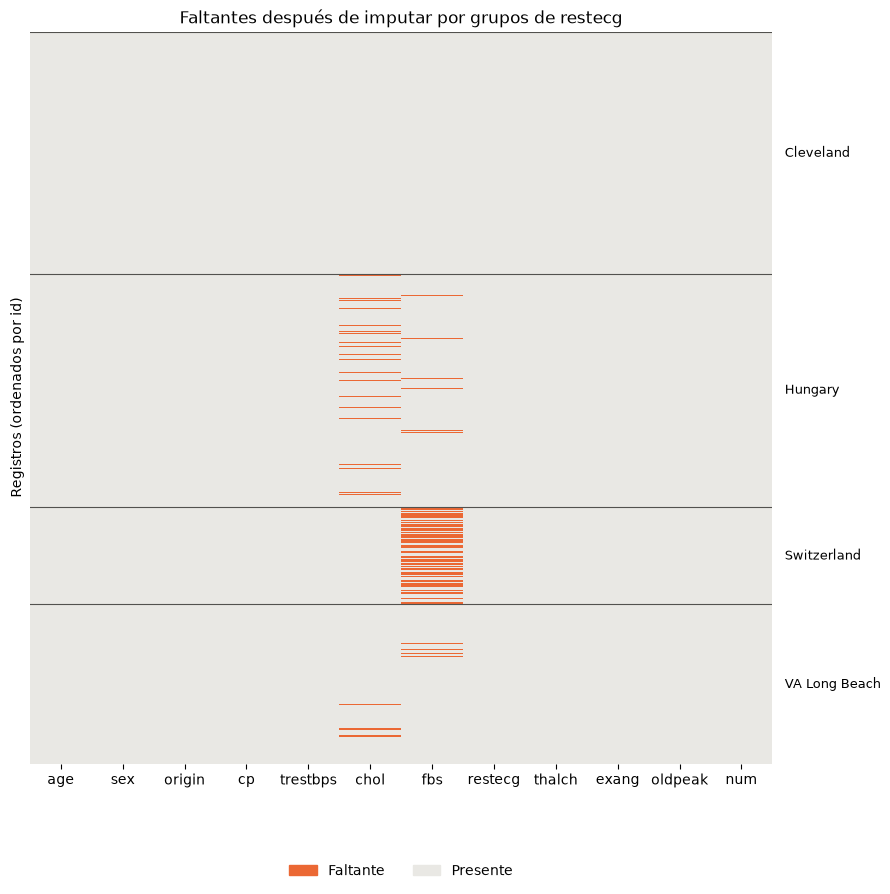

In [83]:
graficar_faltantes(cardio_df, 'Faltantes después de imputar por grupos de restecg')

In [84]:
# Verificación crítica: ¿qué valores recibieron los pacientes imputados y cómo se comparan con su centro?
imputados = antes_p6['thalch'].isna()
print('Valores imputados en thalch (valor: n):', cardio_df.loc[imputados, 'thalch'].value_counts().to_dict())
print('Centro de los pacientes imputados:', cardio_df.loc[imputados, 'origin'].value_counts().to_dict())
print('\nMediana OBSERVADA de thalch por centro:')
print(antes_p6['thalch'].groupby(cardio_df['origin'], observed=True).median().to_string())
print('\nMediana OBSERVADA de thalch por centro y restecg (alternativa de agrupación):')
print(antes_p6['thalch'].groupby([cardio_df['origin'], cardio_df['restecg']], observed=True).median().unstack().to_string())

Valores imputados en thalch (valor: n): {129.0: 29, 140.0: 19, 146.0: 7}
Centro de los pacientes imputados: {'VA Long Beach': 53, 'Hungary': 1, 'Switzerland': 1, 'Cleveland': 0}

Mediana OBSERVADA de thalch por centro:
origin
Cleveland        153.0
Hungary          140.0
Switzerland      121.0
VA Long Beach    120.0

Mediana OBSERVADA de thalch por centro y restecg (alternativa de agrupación):
restecg        lv hypertrophy  normal  st-t abnormality
origin                                                 
Cleveland               150.0   158.0             123.5
Hungary                 135.0   140.0             137.0
Switzerland             125.0   120.0             122.0
VA Long Beach           119.5   120.0             126.0


7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.

In [86]:
faltantes_restantes = cardio_df.isna().sum()
faltantes_restantes[faltantes_restantes > 0]

chol    30
fbs     89
dtype: int64

In [39]:
# Información para elegir la estrategia de cada variable
print(f"chol -> media = {cardio_df['chol'].mean():.1f}, mediana = {cardio_df['chol'].median():.1f}, "
      f"sesgo = {cardio_df['chol'].skew():.2f}, curtosis = {cardio_df['chol'].kurt():.2f}, "
      f"máx = {cardio_df['chol'].max():.0f}")
print('\nfbs (% sobre los valores observados):')
print(cardio_df['fbs'].value_counts(normalize=True).mul(100).round(1).to_string())

chol -> media = 242.2, mediana = 223.0, sesgo = 1.64, curtosis = 6.57, máx = 603

fbs (% sobre los valores observados):
fbs
False    83.4
True     16.6


In [40]:
# chol: numérica, muy asimétrica y con atípicos -> mediana
imp_mediana = SimpleImputer(strategy='median')
cardio_df[['chol']] = imp_mediana.fit_transform(cardio_df[['chol']])
print('Valor imputado en chol (mediana):', imp_mediana.statistics_[0])

# fbs: categórica binaria -> valor más frecuente (moda).
# Se pasa a object porque SimpleImputer trabaja con arreglos de NumPy; después se recupera el tipo category.
imp_moda = SimpleImputer(strategy='most_frequent')
fbs_imputada = imp_moda.fit_transform(cardio_df[['fbs']].astype(object)).ravel()
cardio_df['fbs'] = pd.Series(fbs_imputada, index=cardio_df.index).astype(cardio_df['fbs'].dtype)
print('Valor imputado en fbs (moda):', imp_moda.statistics_[0])

print(f'\nTotal de faltantes en el dataframe: {cardio_df.isna().sum().sum()}')

Valor imputado en chol (mediana): 223.0
Valor imputado en fbs (moda): False

Total de faltantes en el dataframe: 0


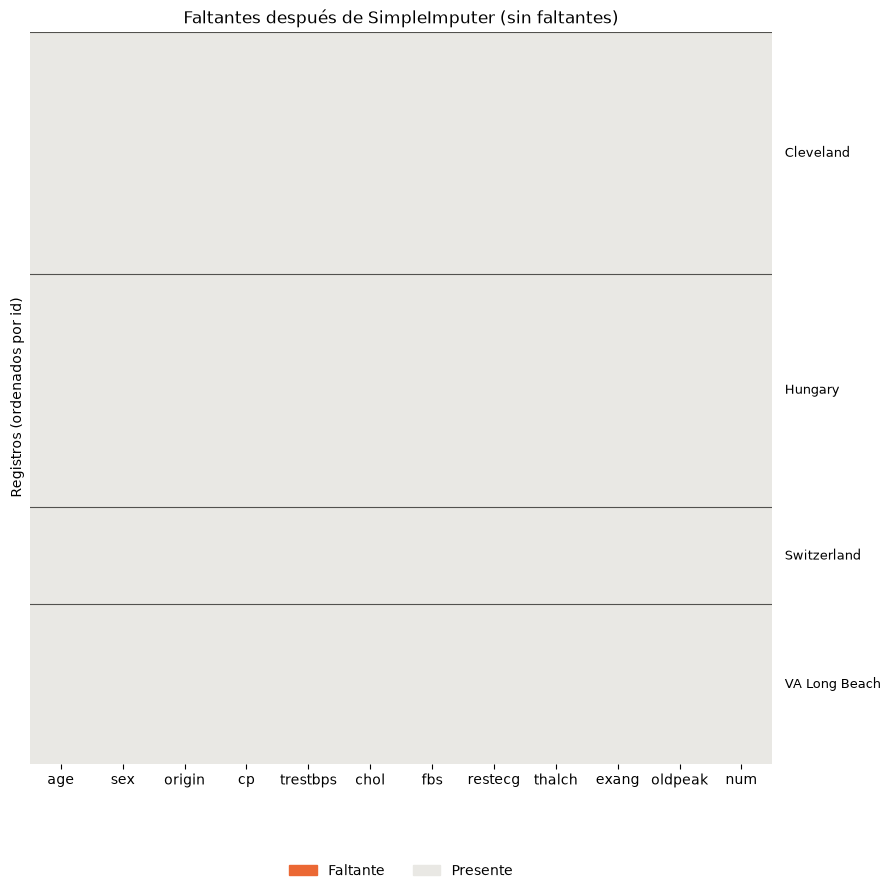

In [41]:
graficar_faltantes(cardio_df, 'Faltantes después de SimpleImputer (sin faltantes)')

**Respuestas – Pregunta 7: justificación de las estrategias**

| Variable | Tipo | Estrategia | Justificación |
|---|---|---|---|
| `chol` (30 NaN) | Numérica continua | **`median`** (223) | Distribución muy asimétrica a la derecha (sesgo 1.64) y de colas pesadas (curtosis 6.6), con valores de hasta 603 mg/dl. La media (242.2) se ve arrastrada por la cola derecha y la mediana es robusta. `mean` solo sería adecuada para una variable aproximadamente simétrica y sin atípicos (Esto porque se corre el riesgo de asumir inadecuadamente que la disribución se "agrupa" cercad e la media). |
| `fbs` (89 NaN) | Categórica binaria (nominal) | **`most_frequent`** (False) | En una variable nominal, la media y la mediana no tienen interpretación. La moda es la única estadística válida, y False representa el 83.4% de los valores observados. |

*Nota:*

* La mediana de `chol` es precisamente **223, el valor de relleno detectado en la sección 3.3**. Imputarla añade 30 casos más al pico artificial. Sin los valores de relleno, la mediana sería 240. (esto me lo hizo notar Claude)

Tras este paso el dataframe ya **no tiene faltantes**, como se ve en el mapa de calor.


Aquí una aclaración que no puse, otros metodos de imputación "aplanan" la media global del indicador y por tanto vale la pena observar el cambio en la distribución. 

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

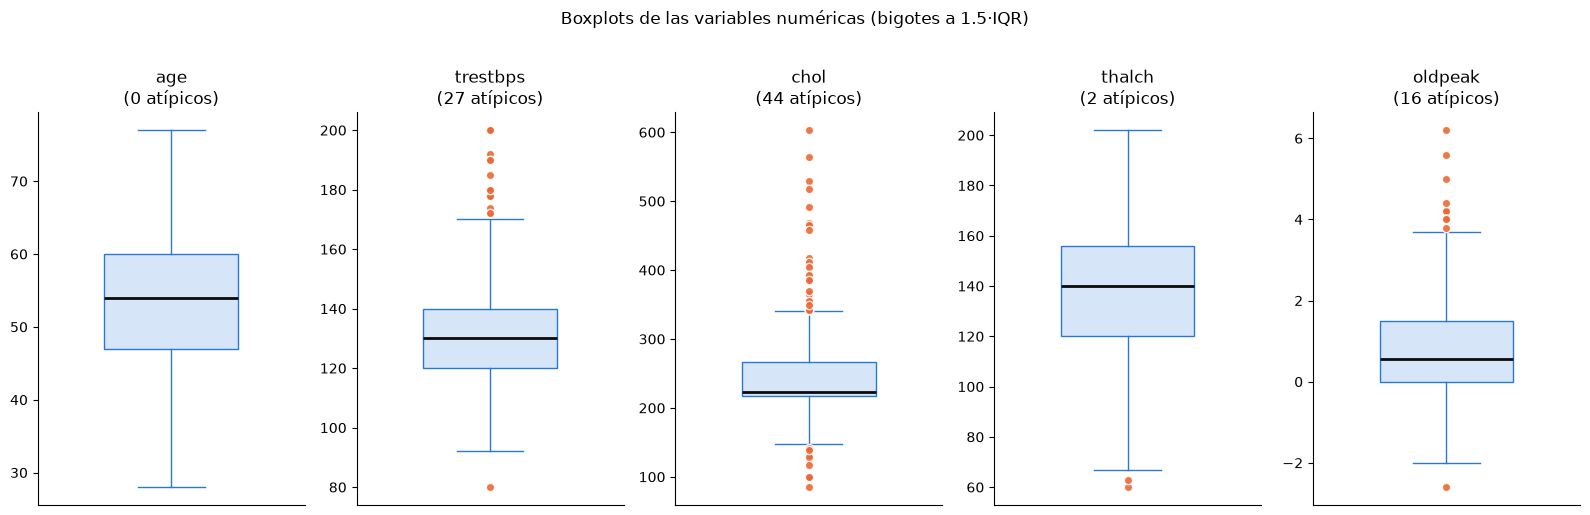

In [42]:
cols_numericas = cardio_df.select_dtypes(include='number').columns.tolist()

fig, axes = plt.subplots(1, len(cols_numericas), figsize=(16, 5))
atipicos_grafico = {}
for ax, col in zip(axes, cols_numericas):
    bp = ax.boxplot(cardio_df[col], widths=0.5, patch_artist=True,          # whis = 1.5 (valor por defecto)
                    boxprops=dict(facecolor='#d6e6f8', edgecolor=COLOR_SIN),
                    medianprops=dict(color='#0b0b0b', linewidth=2),
                    whiskerprops=dict(color=COLOR_SIN), capprops=dict(color=COLOR_SIN),
                    flierprops=dict(marker='o', markersize=6, markerfacecolor=COLOR_CON,
                                    markeredgecolor='white', alpha=0.9))
    # Método gráfico: los atípicos son los puntos 'fliers' del objeto que devuelve boxplot
    atipicos_grafico[col] = np.sort(bp['fliers'][0].get_ydata())
    ax.set_title(f'{col}\n({len(atipicos_grafico[col])} atípicos)')
    ax.set_xticks([])
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Boxplots de las variables numéricas (bigotes a 1.5·IQR)', y=1.02)
plt.tight_layout()
plt.show()

In [43]:
for col, valores in atipicos_grafico.items():
    print(f'{col}: {len(valores)} atípicos')
    if len(valores):
        print('   valores:', valores)

age: 0 atípicos
trestbps: 27 atípicos
   valores: [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
chol: 44 atípicos
   valores: [ 85. 100. 100. 117. 126. 129. 131. 132. 139. 141. 142. 342. 342. 342.
 344. 347. 349. 353. 354. 355. 358. 360. 365. 369. 384. 385. 388. 392.
 393. 394. 394. 404. 407. 409. 412. 417. 458. 466. 468. 491. 518. 529.
 564. 603.]
thalch: 2 atípicos
   valores: [60. 63.]
oldpeak: 16 atípicos
   valores: [-2.6  3.8  4.   4.   4.   4.   4.   4.   4.   4.   4.2  4.2  4.4  5.
  5.6  6.2]


9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [44]:
Q1 = cardio_df['trestbps'].quantile(0.25)
Q3 = cardio_df['trestbps'].quantile(0.75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR
print(f'Q1 = {Q1} | Q3 = {Q3} | IQR = {IQR}')
print(f'Límite inferior = {lim_inf} | Límite superior = {lim_sup}')

mask_atipicos = (cardio_df['trestbps'] < lim_inf) | (cardio_df['trestbps'] > lim_sup)
atipicos_iqr = cardio_df.loc[mask_atipicos, 'trestbps']
print(f'\nAtípicos por IQR: {len(atipicos_iqr)} '
      f'({(atipicos_iqr < lim_inf).sum()} por debajo, {(atipicos_iqr > lim_sup).sum()} por encima)')
print(atipicos_iqr.value_counts().sort_index().rename('frecuencia').to_string())

Q1 = 120.0 | Q3 = 140.0 | IQR = 20.0
Límite inferior = 90.0 | Límite superior = 170.0

Atípicos por IQR: 27 (1 por debajo, 26 por encima)
trestbps
80.0      1
172.0     2
174.0     1
178.0     3
180.0    12
185.0     1
190.0     2
192.0     1
200.0     4


In [45]:
coinciden = np.array_equal(np.sort(atipicos_iqr.to_numpy()), atipicos_grafico['trestbps'])
print(f'Atípicos del boxplot (fliers): {len(atipicos_grafico["trestbps"])} | por IQR: {len(atipicos_iqr)}')
print('¿Coinciden exactamente ambos métodos?', coinciden)

Atípicos del boxplot (fliers): 27 | por IQR: 27
¿Coinciden exactamente ambos métodos? True


10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

In [46]:
trestbps_antes = cardio_df['trestbps'].copy()
n_antes = len(cardio_df)
num_eliminados = cardio_df.loc[mask_atipicos, 'num'].value_counts().sort_index()

cardio_df = cardio_df.loc[~mask_atipicos].copy()

print(f'Registros antes: {n_antes} | eliminados: {mask_atipicos.sum()} | después: {len(cardio_df)}')
print(f"Rango de trestbps depurado: {cardio_df['trestbps'].min():.0f} a {cardio_df['trestbps'].max():.0f} mmHg")
print('Diagnóstico (num) de los registros eliminados:', num_eliminados.to_dict())

Registros antes: 918 | eliminados: 27 | después: 891
Rango de trestbps depurado: 92 a 170 mmHg
Diagnóstico (num) de los registros eliminados: {0: 10, 1: 9, 2: 1, 3: 6, 4: 1}


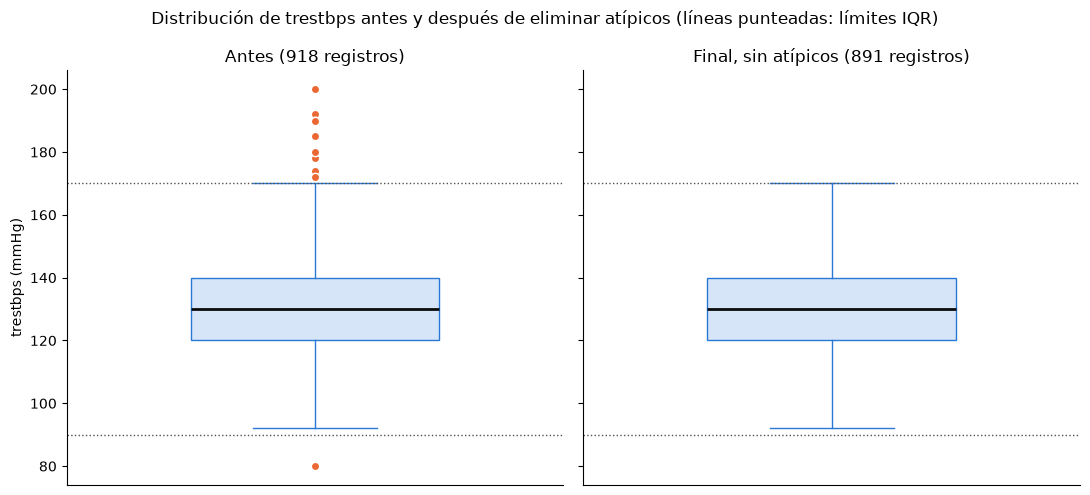

Atípicos en el boxplot final: 0
Nuevos cuartiles: [120.0, 140.0]


In [47]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
estilo = dict(widths=0.5, patch_artist=True,
              boxprops=dict(facecolor='#d6e6f8', edgecolor=COLOR_SIN),
              medianprops=dict(color='#0b0b0b', linewidth=2),
              whiskerprops=dict(color=COLOR_SIN), capprops=dict(color=COLOR_SIN),
              flierprops=dict(marker='o', markersize=6, markerfacecolor=COLOR_CON, markeredgecolor='white'))

axes[0].boxplot(trestbps_antes, **estilo)
axes[0].set_title(f'Antes ({len(trestbps_antes)} registros)')
bp_final = axes[1].boxplot(cardio_df['trestbps'], **estilo)
axes[1].set_title(f'Final, sin atípicos ({len(cardio_df)} registros)')
for ax in axes:
    ax.set_xticks([])
    ax.axhline(lim_inf, color='#52514e', ls=':', lw=1)
    ax.axhline(lim_sup, color='#52514e', ls=':', lw=1)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('trestbps (mmHg)')
fig.suptitle('Distribución de trestbps antes y después de eliminar atípicos (líneas punteadas: límites IQR)')
plt.tight_layout()
plt.show()

print('Atípicos en el boxplot final:', len(bp_final['fliers'][0].get_ydata()))
print('Nuevos cuartiles:', cardio_df['trestbps'].quantile([0.25, 0.75]).tolist())

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---

**Declaración de uso de IA de esta entrega:**

*   Anthropic. (2026). *Claude (Claude Opus 5.5)* [Modelo de lenguaje grande], utilizado para generación de código de todas las graficas, la depuración de codigo (ya que en toda la pregunta 5 tuve problemas) e interpretación de algunos de los resultados respecto a los estadisticos de las desagregaciones de la pregunta 4 y 5 (ya que necestiaba expertice en el area para notar algunas cosas). Esto derivó en que hiciera un plan con asistencia de Claude para desagregar el analisis por ejemplo esto fue notorio para la pregunta de los MAR y MCAR, cuando he enfrentado esto en la vida laboral tengo una intuición mucho mejor para establecer un mecansimo probatorio o al menos de hipotesis, este no fue el caso. Esta vez lo use también para darle formato al markdown (formato tabular y de presentacion de los resultados)

Las preguntas 9 y 10 mi codigo lo tuve que reformular por completo con Claude porque no estaba cerca de la sintaxis correcta. La idea si pero la sintaxis no. 

Para esta tarea si me apoye mucho más de lo usual en claude ya que había que revisar muchas cosas que estaban fuera de mi expertice lo cual lo hizo más retador, siento que algunas de mis intuiciones no eran correctas y que algunas de mis explicaciones no eran acertadas porque me faltaba contexto (por ejemplo, ante mejor información ruve que reformular algunas cosas como el que se repitieran muchas observacioens o sobre los MAR) y el criterio técnico (basicamente conocer del area médica para poder emitir mejores respuestas). 

En conclución: Estar fuera por completo de mi dominio tematico me hizo depender muchismo más de la AI para acercarme a una resupuesta funcional, si sirve como nota esto me hizo repensar lo dificil que es establecer hipotesis adecuadas cuando no hay dominio tématico, de naturaleza y fuente de los datos. 